# Final project: tracking the Husky A200

This notebook calibrates the stereo camera, rectifies the images, computes disparity and the 3-D scene, detects the robot, and tracks it in 2-D and 3-D through occlusions, using only methods from the course. `Approach tests.ipynb` holds the comparisons behind the choices made here, and the study book's [chapter 10](../Study_Book/10_final_project.md) explains them.

Run it from top to bottom in about 7 minutes. Slow results are stored in `results/`, so later runs take about 1 minute. Delete that folder to compute everything again.

#### Setup
The paths and the main settings are at the top. `SQUARE_SIZE` sets the metric scale of all the 3-D results. The board's squares are 80 × 80 mm, as given by the professor; the project description doesn't state it.

In [2]:
import glob
import os
import time

import cv2
import imutils
import numpy as np
from matplotlib import pyplot as plt
from sklearn import linear_model

RESULTS = 'results'
os.makedirs(RESULTS, exist_ok=True)

SEQUENCES = ['1_no_obstacle', '2_obstacle', '3_curved_bend', '4_circle']
IMAGE_SIZE = (1280, 720)

BOARD = (7, 5)              # inner corners of the calibration board
SQUARE_SIZE = 0.080         # metres per square: 80 mm, given by the professor
USE_SUBPIX = False          # <- cornerSubPix is not in the course material; delete results/ after changing this
RECTIFY_ALPHA = 0.15        # <- tweak: 0 crops to valid pixels, 1 keeps all of them
NUM_DISPARITIES = 64        # <- tweak: a multiple of 16
BLOCK_SIZE = 15             # <- tweak: odd
FG_THRESHOLD = 18           # <- tweak: difference from the background that counts as foreground
MIN_AREA = 1000             # <- tweak: smaller blobs are not the robot
MOTION_NOISE_2D = 0.3       # <- tweak: pixels per frame squared
MOTION_NOISE_3D = 0.1 * SQUARE_SIZE     # <- tweak: metres per frame squared
SIZE_LIMIT = 0.85           # a box narrower than this share of the usual width is cut off
GATE = 13.8                 # squared Mahalanobis distance: 99.9 % for 2 degrees of freedom


def image_files(sequence, side):
    return sorted(glob.glob(os.path.join(sequence, sequence, side, '*.png')))

#### 1. Finding the board's corners
`cv2.findChessboardCorners` from Class 4 was used to find the corners. The board is small in the image, so each image is also tried at larger scales with `cv2.resize`, which finds the board in more images. The board has an even number of squares in both directions, which makes its corner order ambiguous by 180°, so each list is put in the same left-to-right order. `USE_SUBPIX` can switch on `cv2.cornerSubPix`, which no course material shows; it is off here, and chapter 10 of the study book lists what it changes.

In [3]:
def find_corners(path):
    gray = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    for scale in (1, 1.5, 2, 2.5, 3):
        big = cv2.resize(gray, None, fx=scale, fy=scale)
        found, corners = cv2.findChessboardCorners(big, BOARD)
        if found:
            corners = (corners.reshape(-1, 2) / scale).astype(np.float32)
            if USE_SUBPIX:
                criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.01)
                corners = cv2.cornerSubPix(gray, corners.reshape(-1, 1, 2), (5, 5), (-1, -1), criteria).reshape(-1, 2)
            if corners[-1, 0] < corners[0, 0]:
                corners = corners[::-1]
            return corners
    return None


corners_file = os.path.join(RESULTS, 'corners.npy')
if os.path.exists(corners_file):
    left_corners, right_corners = np.load(corners_file, allow_pickle=True)
else:
    left_corners = [find_corners(p) for p in image_files('0_calib', 'left')]
    right_corners = [find_corners(p) for p in image_files('0_calib', 'right')]
    stored = np.empty(2, dtype=object)
    stored[0], stored[1] = left_corners, right_corners
    np.save(corners_file, stored)

print("board found in", sum(c is not None for c in left_corners), "left and",
      sum(c is not None for c in right_corners), "right images, of", len(left_corners))

board found in 23 left and 21 right images, of 37


#### 2. Calibrating and rectifying
A few corners in each image are off by 5 to 8 px, while the rest fit within 1 px. RANSAC with a homography, from Classes 2 and 4, was used to remove those corners: the board is planar, so all its corners must agree with one homography. `cv2.calibrateCamera` then gives each camera's K and distortion, `cv2.stereoCalibrate` the pose between the cameras, and `cv2.stereoRectify` with `cv2.initUndistortRectifyMap` the rectifying maps. `RECTIFY_ALPHA` is 0.15, the largest tested value with no folded pixels: above it, the distortion formula folds back at the image's edge, which creates a mirror image of the robot.

In [4]:
GRID = np.zeros((BOARD[0] * BOARD[1], 3), np.float32)
GRID[:, :2] = np.mgrid[0:BOARD[0], 0:BOARD[1]].T.reshape(-1, 2) * SQUARE_SIZE


def planar_corners(corners):
    _, mask = cv2.findHomography(GRID[:, :2], corners, cv2.RANSAC, 1.0)
    return mask.ravel() == 1


objects_l, images_l, objects_r, images_r, objects_s, stereo_l, stereo_r = [], [], [], [], [], [], []
removed = 0
for left, right in zip(left_corners, right_corners):
    good_l = planar_corners(left) if left is not None else None
    good_r = planar_corners(right) if right is not None else None
    if left is not None:
        objects_l.append(GRID[good_l])
        images_l.append(left[good_l])
    if right is not None:
        objects_r.append(GRID[good_r])
        images_r.append(right[good_r])
    if left is not None and right is not None and np.sum(good_l & good_r) >= 12:
        both = good_l & good_r
        removed += len(GRID) - np.sum(both)
        objects_s.append(GRID[both])
        stereo_l.append(left[both])
        stereo_r.append(right[both])

rms_l, K1, d1, _, _ = cv2.calibrateCamera(objects_l, images_l, IMAGE_SIZE, None, None)
rms_r, K2, d2, _, _ = cv2.calibrateCamera(objects_r, images_r, IMAGE_SIZE, None, None)
rms_s, K1, d1, K2, d2, R, T, E, F = cv2.stereoCalibrate(objects_s, stereo_l, stereo_r, K1, d1, K2, d2, IMAGE_SIZE,
                                                        flags=cv2.CALIB_FIX_INTRINSIC)
R1, R2, P1, P2, Q, _, _ = cv2.stereoRectify(K1, d1, K2, d2, IMAGE_SIZE, R, T, alpha=RECTIFY_ALPHA)
map_l = cv2.initUndistortRectifyMap(K1, d1, R1, P1, IMAGE_SIZE, cv2.CV_32FC1)
map_r = cv2.initUndistortRectifyMap(K2, d2, R2, P2, IMAGE_SIZE, cv2.CV_32FC1)

FOCAL, CX, CY = P1[0, 0], P1[0, 2], P1[1, 2]
BASELINE = -P2[0, 3] / P2[0, 0]

# rectification can leave black margins: the robot is then cut off at these columns, not at the image's edge
valid = (map_l[0] >= 0) & (map_l[0] < IMAGE_SIZE[0]) & (map_l[1] >= 0) & (map_l[1] < IMAGE_SIZE[1])
LEFT_LIMIT = max(np.flatnonzero(valid[row])[0] for row in range(300, 650))
RIGHT_LIMIT = min(np.flatnonzero(valid[row])[-1] for row in range(300, 650))

np.savez(os.path.join(RESULTS, 'calibration.npz'), K1=K1, d1=d1, K2=K2, d2=d2, R=R, T=T, R1=R1, R2=R2, P1=P1, P2=P2, Q=Q)

print("views: left", len(images_l), "right", len(images_r), "stereo", len(stereo_l), "| corners removed:", removed)
print("reprojection error [px]: left", round(rms_l, 3), "right", round(rms_r, 3), "stereo", round(rms_s, 3))
print("focal lengths [px]:", K1[0, 0].round(1), K2[0, 0].round(1), "| rectified:", FOCAL.round(1))
print("baseline:", round(BASELINE, 4), "m =", round(BASELINE / SQUARE_SIZE, 3), "squares")
print("valid columns:", LEFT_LIMIT, "to", RIGHT_LIMIT)
print("rotation between the cameras [deg]:", np.degrees(cv2.Rodrigues(R)[0].ravel()).round(3))


def rectified(path, side):
    maps = map_l if side == 'left' else map_r
    return cv2.remap(cv2.imread(path), maps[0], maps[1], cv2.INTER_LINEAR)

views: left 23 right 21 stereo 19 | corners removed: 78
reprojection error [px]: left 0.343 right 0.282 stereo 0.43
focal lengths [px]: 620.0 617.2 | rectified: 689.9
baseline: 0.1224 m = 1.53 squares
valid columns: 1 to 1279
rotation between the cameras [deg]: [-0.531 -0.373 -0.044]


#### 3. Checking the rectification
A calibration can look good on the board and still be wrong elsewhere, so it is checked on the scene. SIFT with the ratio test, from Class 2, was used to match points between the left and right image of real frames. After rectification, matching points must lie on the same row. The plot shows one rectified pair with some of the matches, whose lines should be horizontal.

row difference of matched points [px]
  raw:       median 17.84 90 % 18.86 n 2807
  rectified: median 0.63 90 % 1.79 n 1874


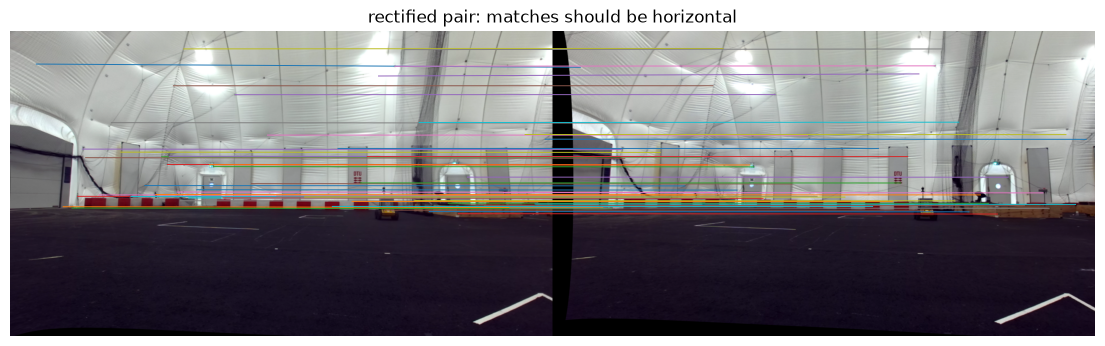

In [5]:
def match_points(left, right):
    sift = cv2.SIFT_create(4000)
    kp1, des1 = sift.detectAndCompute(cv2.cvtColor(left, cv2.COLOR_BGR2GRAY), None)
    kp2, des2 = sift.detectAndCompute(cv2.cvtColor(right, cv2.COLOR_BGR2GRAY), None)
    good = [m for m, n in cv2.BFMatcher(cv2.NORM_L2).knnMatch(des1, des2, k=2) if m.distance < 0.7 * n.distance]
    return np.float32([kp1[m.queryIdx].pt for m in good]), np.float32([kp2[m.trainIdx].pt for m in good])


raw_rows, rect_rows = [], []
for sequence, frame in (('1_no_obstacle', 10), ('3_curved_bend', 200), ('4_circle', 400)):
    path_l, path_r = image_files(sequence, 'left')[frame], image_files(sequence, 'right')[frame]
    a, b = match_points(cv2.imread(path_l), cv2.imread(path_r))
    raw_rows.append(np.abs(a[:, 1] - b[:, 1]))
    left, right = rectified(path_l, 'left'), rectified(path_r, 'right')
    pts_l, pts_r = match_points(left, right)
    rect_rows.append(np.abs(pts_l[:, 1] - pts_r[:, 1]))

raw_rows, rect_rows = np.concatenate(raw_rows), np.concatenate(rect_rows)
print("row difference of matched points [px]")
print("  raw:       median", np.median(raw_rows).round(2), "90 %", np.percentile(raw_rows, 90).round(2), "n", len(raw_rows))
print("  rectified: median", np.median(rect_rows).round(2), "90 %", np.percentile(rect_rows, 90).round(2), "n", len(rect_rows))

pair = np.hstack([left, right])
plt.figure(figsize=(14, 4))
plt.imshow(cv2.cvtColor(pair, cv2.COLOR_BGR2RGB))
for p, q in zip(pts_l[::12], pts_r[::12]):
    plt.plot([p[0], q[0] + IMAGE_SIZE[0]], [p[1], q[1]], linewidth=0.7)
plt.axis('off')
plt.title('rectified pair: matches should be horizontal')
plt.show()

#### 4. Background, disparity and the floor
The cameras don't move, so the median of frames spread over a sequence removes everything that moves and leaves the empty scene. `cv2.StereoBM_create` from Class 3 was used to compute disparity, and `cv2.reprojectImageTo3D` to turn it into 3-D points. `linear_model.RANSACRegressor` from Class 6 then fits the floor as Y = aX + bZ + c. The floor gives a bird's-eye view of the tracks, and an independent check of them in part 9.

In [6]:
def median_background(sequence, side):
    files = image_files(sequence, side)
    picks = np.linspace(0, len(files) - 1, 41).astype(int)
    return np.median(np.stack([rectified(files[i], side) for i in picks]), axis=0).astype(np.uint8)


block_matcher = cv2.StereoBM_create(numDisparities=NUM_DISPARITIES, blockSize=BLOCK_SIZE)


def disparity_map(left, right):
    gray_l, gray_r = cv2.cvtColor(left, cv2.COLOR_BGR2GRAY), cv2.cvtColor(right, cv2.COLOR_BGR2GRAY)
    return block_matcher.compute(gray_l, gray_r).astype(np.float32) / 16


def fit_floor(left, right):
    disparity = disparity_map(left, right)
    points = cv2.reprojectImageTo3D(disparity, Q)
    points = points[480:][disparity[480:] > 5][::5]        # the part of the image below the horizon
    points = points[np.abs(points).max(axis=1) < 300 * SQUARE_SIZE]
    model = linear_model.RANSACRegressor(residual_threshold=0.5 * SQUARE_SIZE, random_state=0)
    model.fit(points[:, [0, 2]], points[:, 1])
    a, b = model.estimator_.coef_
    length = np.linalg.norm([a, -1, b])
    return np.array([a, -1, b]) / length, model.estimator_.intercept_ / length, model.inlier_mask_.mean()


backgrounds, floors = {}, {}
for sequence in SEQUENCES:
    file_l = os.path.join(RESULTS, sequence + '_background_left.png')
    file_r = os.path.join(RESULTS, sequence + '_background_right.png')
    if not os.path.exists(file_l):
        cv2.imwrite(file_l, median_background(sequence, 'left'))
        cv2.imwrite(file_r, median_background(sequence, 'right'))
    backgrounds[sequence] = cv2.imread(file_l), cv2.imread(file_r)
    normal, height, inliers = fit_floor(*backgrounds[sequence])
    floors[sequence] = normal, height
    disparity = disparity_map(*backgrounds[sequence])
    print(sequence, "valid disparity", round(np.mean(disparity > 0), 3), "| floor normal", normal.round(3),
          "| camera height", round(height, 3), "m | inliers", round(inliers, 3))

1_no_obstacle valid disparity 0.663 | floor normal [-0.001 -0.999  0.055] | camera height 0.758 m | inliers 0.924
2_obstacle valid disparity 0.686 | floor normal [-0.005 -0.999  0.047] | camera height 0.785 m | inliers 0.797
3_curved_bend valid disparity 0.659 | floor normal [-0.003 -0.999  0.049] | camera height 0.773 m | inliers 0.895
4_circle valid disparity 0.657 | floor normal [-0.007 -0.999  0.053] | camera height 0.764 m | inliers 0.888


#### 5. Detecting the robot
Background subtraction, thresholding, erosion and dilation from Class 1 were used to find what differs from the empty scene. The difference is taken per channel with plain NumPy, and the largest channel counts, so a colour change is seen even when the brightness barely changes. `cv2.findContours` gives the blobs, and the largest is taken as the robot. The robot's black body on the dark floor can split into pieces, such as the mast, so blobs close to the largest are merged into one box. The robot's disparity is the median of `StereoBM` over its foreground pixels, which was the steadiest of the four methods tested in `Approach tests.ipynb`.

1_no_obstacle frames 256 | robot seen in 147 | median area 18524 px
2_obstacle frames 291 | robot seen in 131 | median area 12679 px
3_curved_bend frames 397 | robot seen in 350 | median area 4602 px
4_circle frames 650 | robot seen in 650 | median area 2307 px
time: 0.0 s


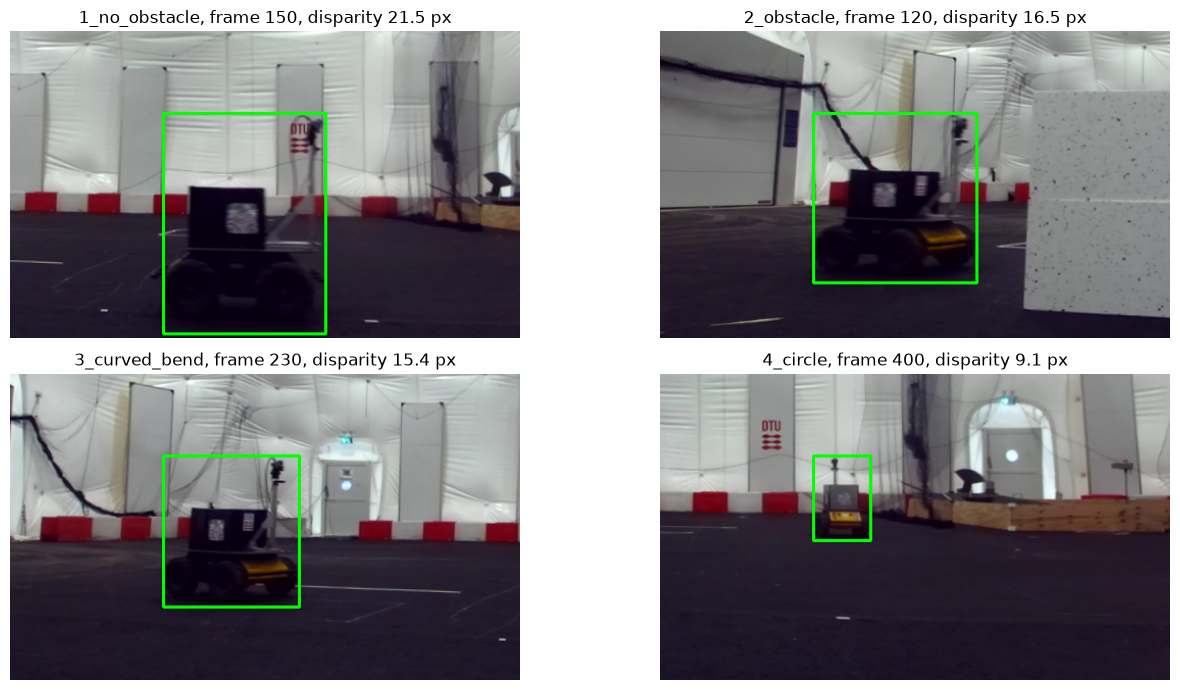

In [7]:
def foreground(image, background):
    blurred = cv2.GaussianBlur(image, (5, 5), 0)
    difference = np.abs(blurred.astype(int) - background.astype(int)).max(axis=2)
    mask = (difference > FG_THRESHOLD).astype(np.uint8) * 255
    return cv2.dilate(cv2.erode(mask, None, iterations=1), None, iterations=2)


def largest_box(mask):
    contours = imutils.grab_contours(cv2.findContours(mask.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE))
    blobs = []
    for c in contours:
        x0, x1, y0, y1 = c[:, :, 0].min(), c[:, :, 0].max() + 1, c[:, :, 1].min(), c[:, :, 1].max() + 1
        blobs.append((np.sum(mask[y0:y1, x0:x1] > 0), x0, y0, x1, y1))
    if not blobs:
        return None
    blobs.sort(reverse=True)
    area, x0, y0, x1, y1 = blobs[0]
    w, h = x1 - x0, y1 - y0
    for other, a0, b0, a1, b1 in blobs[1:]:
        if other >= 30 and a0 < x1 + 0.3 * w and a1 > x0 - 0.3 * w and b0 < y1 + 0.3 * h and b1 > y0 - 0.3 * h:
            x0, y0, x1, y1 = min(x0, a0), min(y0, b0), max(x1, a1), max(y1, b1)
    return area, x0, y0, x1 - x0, y1 - y0


def detect(left, right, background):
    """Returns [area, x, y, w, h, disparity, disparity pixels]."""
    mask = foreground(left, background)
    disparity = disparity_map(left, right)
    box = largest_box(mask)
    if box is None:
        return [0, 0, 0, 0, 0, np.nan, 0]
    area, x, y, w, h = box
    inside = disparity[y:y + h, x:x + w]
    values = inside[(mask[y:y + h, x:x + w] > 0) & (inside > 0)]
    return [area, x, y, w, h, np.median(values) if len(values) >= 20 else np.nan, len(values)]


start = time.time()
detections = {}
for sequence in SEQUENCES:
    stored = os.path.join(RESULTS, sequence + '_detections.npy')
    if not os.path.exists(stored):
        background = cv2.GaussianBlur(backgrounds[sequence][0], (5, 5), 0)
        rows = []
        for path_l, path_r in zip(image_files(sequence, 'left'), image_files(sequence, 'right')):
            rows.append(detect(rectified(path_l, 'left'), rectified(path_r, 'right'), background))
        np.save(stored, np.array(rows, float))
    detections[sequence] = np.load(stored)
    seen = detections[sequence][:, 0] >= MIN_AREA
    print(sequence, "frames", len(seen), "| robot seen in", seen.sum(), "| median area", np.median(detections[sequence][seen, 0]).astype(int), "px")
print("time:", round(time.time() - start, 1), "s")

plt.figure(figsize=(14, 7))
for k, (sequence, frame) in enumerate((('1_no_obstacle', 150), ('2_obstacle', 120), ('3_curved_bend', 230), ('4_circle', 400))):
    image = rectified(image_files(sequence, 'left')[frame], 'left')
    _, x, y, w, h, d, _ = detections[sequence][frame].astype(float)
    x, y, w, h = int(x), int(y), int(w), int(h)
    cv2.rectangle(image, (x, y), (x + w, y + h), (0, 255, 0), 2)
    x0, y0 = max(0, x - 150), max(0, y - 80)
    plt.subplot(2, 2, k + 1)
    plt.imshow(cv2.cvtColor(image[y0:y0 + 300, x0:x0 + 500], cv2.COLOR_BGR2RGB))
    plt.title(sequence + ', frame ' + str(frame) + ', disparity ' + str(round(d, 1)) + ' px')
    plt.axis('off')
plt.tight_layout()
plt.show()

#### 6. Disparity maps with the robot, and the 3-D scene
For each sequence, the frame where the robot is largest gets a disparity map and a coloured point cloud. `export_pointcloud` from Class 3 writes the `.ply` file, here with the calibrated `Q` instead of the template's guessed one. Far points and every second pixel are left out to keep the files small.

1_no_obstacle frame 186 | points written 117014
2_obstacle frame 215 | points written 126381
3_curved_bend frame 332 | points written 117725
4_circle frame 253 | points written 118293


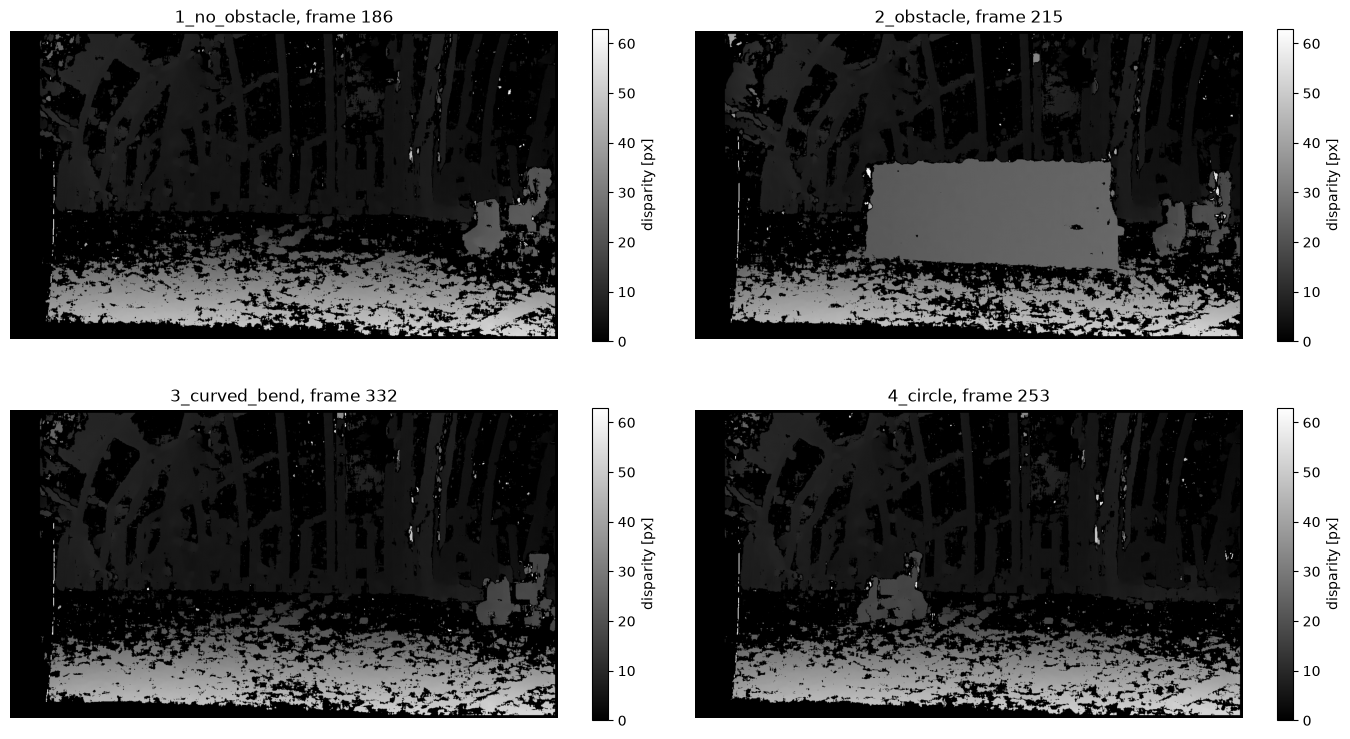

In [8]:
def export_pointcloud(disparity, colors, out_fn):
    ply_header = '''ply
format ascii 1.0
element vertex %(vert_num)d
property float x
property float y
property float z
property uchar red
property uchar green
property uchar blue
end_header
'''
    points = cv2.reprojectImageTo3D(disparity, Q)
    mask = (disparity > 2) & (points[:, :, 2] < 40)
    mask[1::2] = False
    mask[:, 1::2] = False
    verts = np.hstack([points[mask], colors[mask][:, ::-1]])
    with open(out_fn, 'wb') as f:
        f.write((ply_header % dict(vert_num=len(verts))).encode('utf-8'))
        np.savetxt(f, verts, fmt='%f %f %f %d %d %d ')
    return len(verts)


plt.figure(figsize=(14, 8))
for k, sequence in enumerate(SEQUENCES):
    files_l, files_r = image_files(sequence, 'left'), image_files(sequence, 'right')
    frame = int(np.argmax(detections[sequence][:, 0]))
    left, right = rectified(files_l[frame], 'left'), rectified(files_r[frame], 'right')
    disparity = disparity_map(left, right)
    count = export_pointcloud(disparity, left, os.path.join(RESULTS, sequence + '_scene.ply'))
    print(sequence, "frame", frame, "| points written", count)
    plt.subplot(2, 2, k + 1)
    plt.imshow(np.clip(disparity, 0, NUM_DISPARITIES), cmap='gray')
    plt.colorbar(shrink=0.8, label='disparity [px]')
    plt.title(sequence + ', frame ' + str(frame))
    plt.axis('off')
plt.tight_layout()
plt.show()

#### 7. The Kalman filter
The Kalman filter of Class 7, with a constant-velocity model, was used to follow the robot and to predict it when it can't be seen. The same code runs in 2-D, on the image position, and in 3-D, on the position from stereo. The tracked point is the bottom centre of the box, where the wheels meet the floor, because the top of the box jumps when the mast is hidden. Depth noise grows with the square of the distance (Z² Δd / fB, Class 3), so the 3-D measurement noise is set per frame.

Three checks decide what each frame contributes:
- **Full box:** the box must not touch the edge of the valid image area, and must be at least `SIZE_LIMIT` of the usual width. Stereo also gives its real size, which must fit the robot with its mast: 0.6 to 2.2 m wide and 0.8 to 2.2 m high. This rejects, for example, a floor reflection that is only 0.4 m wide. A full box then updates the whole position, if it also passes the gate on the Mahalanobis distance.
- **Cut-off box:** when the board or the image's edge hides part of the robot, the box centre is wrong, but one edge is still right. That edge plus half the usual width gives the sideways position, so only that is updated. The bottom of the box must still be near the predicted row. The disparity is not used here, because the pixels near the board are biased.
- **No box:** the filter only predicts. This is what carries the robot through a complete occlusion.

In [9]:
def to_3d(u, v, d):
    Z = FOCAL * BASELINE / d
    return np.array([(u - CX) * Z / FOCAL, (v - CY) * Z / FOCAL, Z])


def to_image(point):
    return np.array([FOCAL * point[0] / point[2] + CX, FOCAL * point[1] / point[2] + CY])


def motion_model(n, noise):
    F = np.eye(2 * n)
    F[:n, n:] = np.eye(n)
    G = np.vstack([0.5 * np.eye(n), np.eye(n)])
    return F, G @ G.T * noise ** 2


def kalman_update(x, P, z, H, R):
    S = H @ P @ H.T + R
    K = P @ H.T @ np.linalg.inv(S)
    return x + K @ (z - H @ x), (np.eye(len(x)) - K @ H) @ P


def noise_3d(Z, pixels=2.0, disparity_pixels=0.3):
    side = pixels * Z / FOCAL
    depth = Z ** 2 / (FOCAL * BASELINE) * disparity_pixels
    return np.diag([side ** 2, side ** 2, depth ** 2])


def plausible_size(w, h, d):
    if np.isnan(d) or d <= 0:
        return False
    return 0.6 <= w * BASELINE / d <= 2.2 and 0.8 <= h * BASELINE / d <= 2.2


def track(rows, mode, hide=None, use_edges=True):
    """Returns the state per frame (NaN when there is none) and a label per frame:
    none, init, full, edge, predicted, gated or left."""
    n = 2 if mode == '2d' else 3
    F, Q_motion = motion_model(n, MOTION_NOISE_2D if mode == '2d' else MOTION_NOISE_3D)
    H = np.hstack([np.eye(n), np.zeros((n, n))])
    H_side = H[:1]
    states = np.full((len(rows), 2 * n), np.nan)
    labels = ['none'] * len(rows)
    x, P, widths, gated = None, None, [], 0

    for i, (area, bx, by, w, h, d, _) in enumerate(rows):
        seen = area >= MIN_AREA and not (hide is not None and hide[0] <= i < hide[1])
        touches = bx <= LEFT_LIMIT + 2 or bx + w >= RIGHT_LIMIT - 2
        good_box = plausible_size(w, h, d)
        u, v = bx + w / 2, by + h

        if x is None:                                             # start at the first complete box
            if seen and not touches and good_box:
                if mode == '2d':
                    x, P = np.array([u, v, 0, 0.]), np.diag([4, 4, 100, 100.])
                else:
                    point = to_3d(u, v, d)
                    x = np.r_[point, 0, 0, 0.]
                    P = np.zeros((6, 6))
                    P[:3, :3] = noise_3d(point[2])
                    P[3:, 3:] = np.eye(3) * (10 * SQUARE_SIZE) ** 2
                widths = [w]
                states[i], labels[i] = x, 'init'
            continue

        x, P = F @ x, F @ P @ F.T + Q_motion
        label = 'predicted'
        predicted_u, predicted_v = x[:2] if mode == '2d' else to_image(x[:3])

        if seen:
            usual = np.median(widths[-10:])
            if not touches and good_box and w >= SIZE_LIMIT * usual:     # a full box
                z = np.array([u, v]) if mode == '2d' else to_3d(u, v, d)
                R = np.eye(2) * 4.0 if mode == '2d' else noise_3d(z[2])
                y = z - H @ x
                if y @ np.linalg.inv(H @ P @ H.T + R) @ y <= GATE:
                    x, P = kalman_update(x, P, z, H, R)
                    widths.append(w)
                    label, gated = 'full', 0
                else:
                    label, gated = 'gated', gated + 1
                    if gated >= 8:                                # the filter has lost it: accept the box
                        x[:n], P[:n, :n], gated = z, R, 0
                        widths = [w]
            elif use_edges and w >= 8 and abs(v - predicted_v) < 40:     # a cut-off box: use the visible edge
                from_left, from_right = bx + usual / 2, bx + w - usual / 2
                centre = from_left if abs(from_left - predicted_u) < abs(from_right - predicted_u) else from_right
                z = np.array([centre if mode == '2d' else (centre - CX) * x[2] / FOCAL])
                R = np.array([[16.0 if mode == '2d' else noise_3d(x[2], pixels=4.0)[0, 0]]])
                y = z - H_side @ x
                if y @ np.linalg.inv(H_side @ P @ H_side.T + R) @ y <= GATE:
                    x, P = kalman_update(x, P, z, H_side, R)
                    label = 'edge'

        position_u = x[0] if mode == '2d' else to_image(x[:3])[0]
        if position_u < -150 or position_u > IMAGE_SIZE[0] + 150:  # it has left the image
            x, labels[i] = None, 'left'
            continue
        states[i], labels[i] = x, label
    return states, labels

#### 8. Tracking all sequences
Both filters run on every sequence. The table counts what each frame contributed. The first plot draws the 2-D track on the empty scene, and the second the 3-D track from above, in floor coordinates: the 3-D positions are projected onto the plane fitted in part 4. Tracks and labels are stored in `results/`, also as a CSV file.

1_no_obstacle {'edge': 18, 'full': 103, 'init': 1, 'left': 1, 'none': 126, 'predicted': 7}
2_obstacle {'edge': 30, 'full': 45, 'gated': 1, 'init': 1, 'left': 1, 'none': 146, 'predicted': 67}
3_curved_bend {'edge': 18, 'full': 331, 'init': 1, 'left': 1, 'none': 36, 'predicted': 10}
4_circle {'full': 649, 'init': 1}


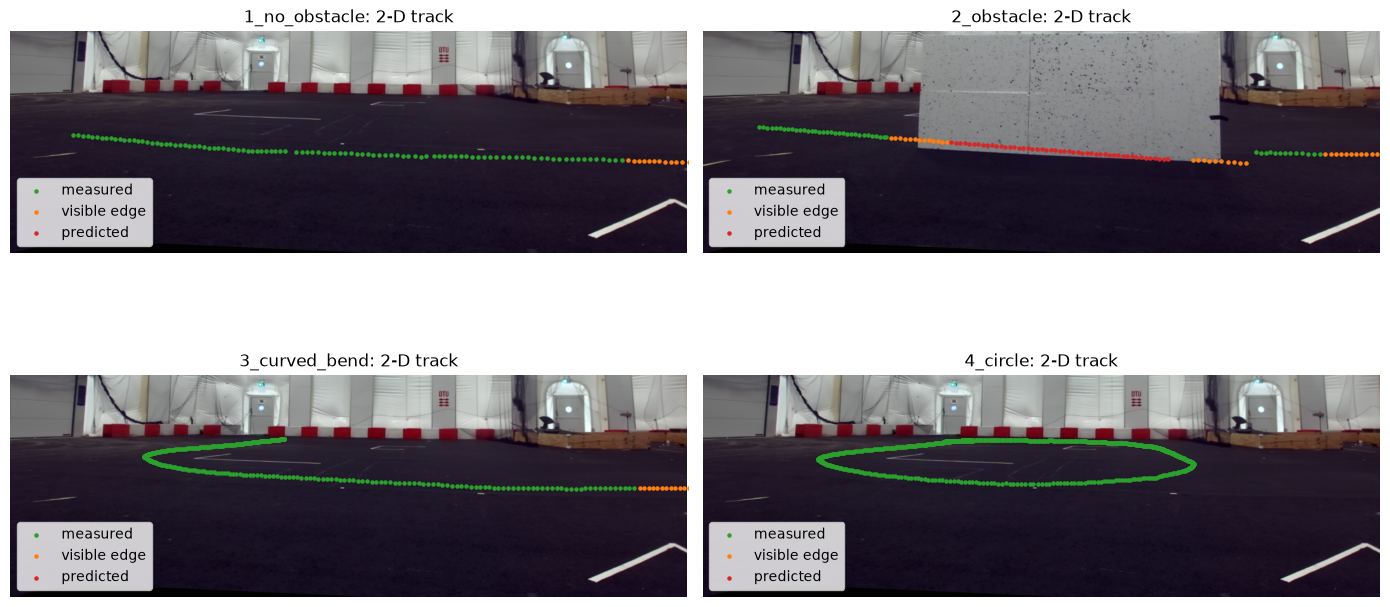

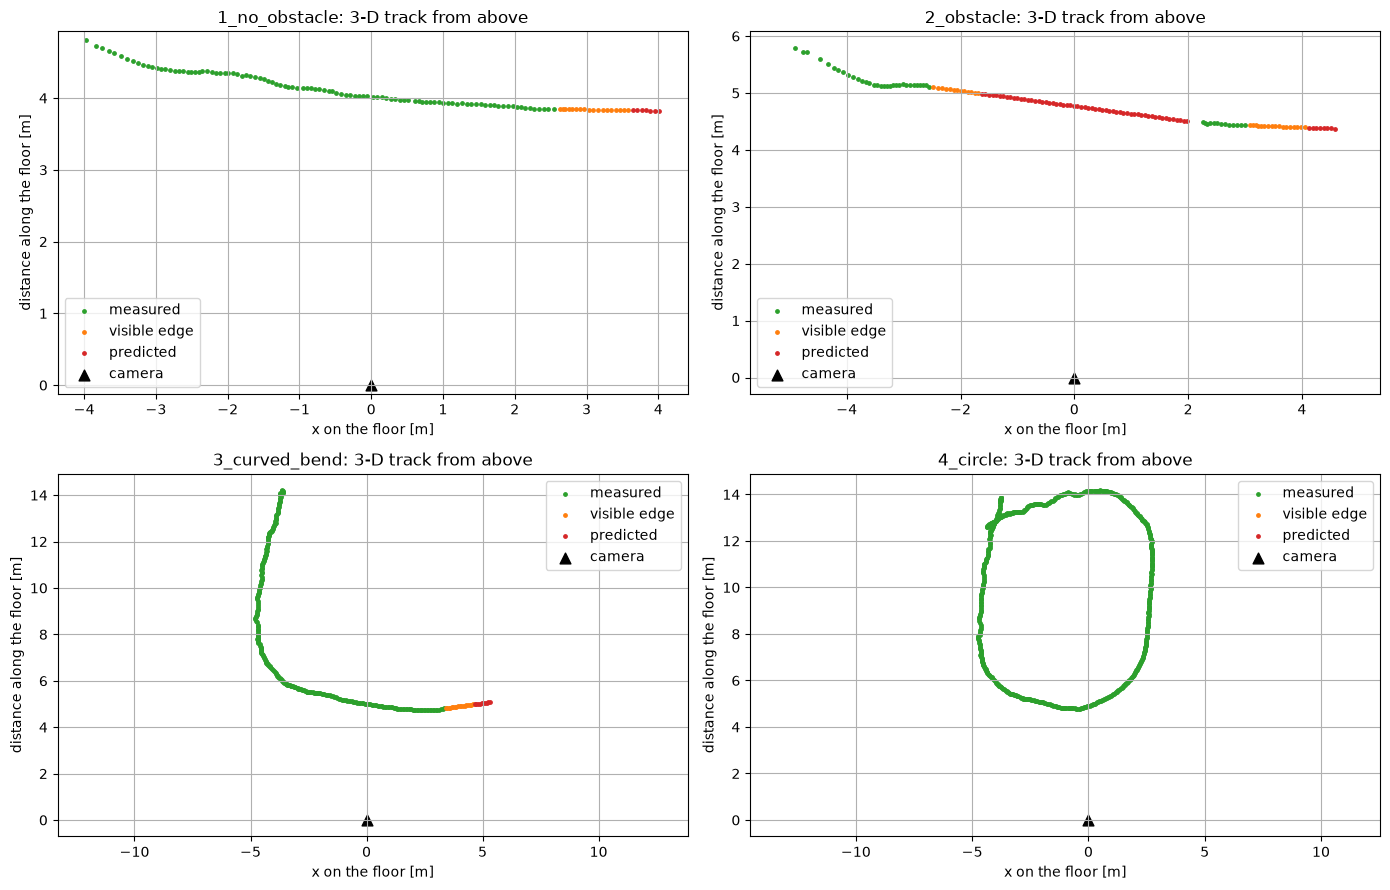

In [10]:
def floor_axes(normal):
    right = np.array([1.0, 0, 0]) - normal[0] * normal
    right = right / np.linalg.norm(right)
    forward = np.cross(right, normal)
    return right, forward if forward[2] > 0 else -forward


def on_floor(points, normal):
    right, forward = floor_axes(normal)
    return np.c_[points @ right, points @ forward]


tracks_2d, tracks_3d, labels_2d, labels_3d = {}, {}, {}, {}
for sequence in SEQUENCES:
    rows = detections[sequence]
    tracks_2d[sequence], labels_2d[sequence] = track(rows, '2d')
    tracks_3d[sequence], labels_3d[sequence] = track(rows, '3d')
    names, counts = np.unique(labels_3d[sequence], return_counts=True)
    print(sequence, dict(zip(names.tolist(), counts.tolist())))
    table = np.c_[np.arange(len(rows)), tracks_2d[sequence][:, :2], tracks_3d[sequence][:, :3]]
    np.savetxt(os.path.join(RESULTS, sequence + '_track.csv'), table, delimiter=',', fmt='%.4f',
               header='frame,u_2d,v_2d,X_m,Y_m,Z_m', comments='')

STYLES = {'full': ('tab:green', 'measured'), 'edge': ('tab:orange', 'visible edge'), 'predicted': ('tab:red', 'predicted')}

plt.figure(figsize=(14, 8))
for k, sequence in enumerate(SEQUENCES):
    plt.subplot(2, 2, k + 1)
    plt.imshow(cv2.cvtColor(backgrounds[sequence][0], cv2.COLOR_BGR2RGB))
    labels = np.array(labels_2d[sequence])
    for name, (colour, text) in STYLES.items():
        chosen = labels == name
        plt.scatter(tracks_2d[sequence][chosen, 0], tracks_2d[sequence][chosen, 1], s=5, color=colour, label=text)
    plt.xlim(0, IMAGE_SIZE[0])
    plt.ylim(IMAGE_SIZE[1], 300)
    plt.axis('off')
    plt.legend(loc='lower left')
    plt.title(sequence + ': 2-D track')
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 9))
for k, sequence in enumerate(SEQUENCES):
    plt.subplot(2, 2, k + 1)
    labels = np.array(labels_3d[sequence])
    ground = on_floor(tracks_3d[sequence][:, :3], floors[sequence][0])
    for name, (colour, text) in STYLES.items():
        chosen = labels == name
        plt.scatter(ground[chosen, 0], ground[chosen, 1], s=6, color=colour, label=text)
    plt.scatter(0, 0, marker='^', s=60, color='black', label='camera')
    plt.axis('equal')
    plt.grid(True)
    plt.xlabel('x on the floor [m]')
    plt.ylabel('distance along the floor [m]')
    plt.legend()
    plt.title(sequence + ': 3-D track from above')
plt.tight_layout()
plt.show()

#### 9. Tests of the 3-D track
There is no ground truth, so the tests use what the project description and the scene guarantee. Sequences 1 and 2 should show a straight path at constant speed and constant distance, which `RANSACRegressor` and plain statistics check. In all sequences the wheels should stay on the floor, whose plane was fitted without using the robot at all. Sequence 4 should be a circle, fitted by linear least squares from Class 6. The last line checks the scale independently, by comparing the robot's measured length with the Husky's published 0.99 m.

The robot is rigid, so its height in pixels must be proportional to its true disparity. A line fitted through height against measured disparity should therefore pass through zero, and its offset shows any bias in the disparity. The second cell tries removing that offset, and checks whether the independent tests agree.

In [11]:
print("straight line and speed, from the 3-D filter (full frames only)")
for sequence in SEQUENCES[:2]:
    chosen = np.array(labels_3d[sequence]) == 'full'
    ground = on_floor(tracks_3d[sequence][chosen, :3], floors[sequence][0])
    model = linear_model.RANSACRegressor(residual_threshold=0.2, random_state=0).fit(ground[:, :1], ground[:, 1])
    residual = ground[:, 1] - model.predict(ground[:, :1])
    speed = np.linalg.norm(tracks_3d[sequence][chosen, 3:6], axis=1)
    print(" ", sequence, "| path length", round(np.ptp(ground[:, 0]), 2), "m | residual from a line", round(residual.std(), 3),
          "m | angle", round(np.degrees(np.arctan(model.estimator_.coef_[0])), 2), "deg | distance", round(ground[:, 1].mean(), 2),
          "m | speed", round(speed.mean(), 4), "+-", round(speed.std(), 4), "m per frame")

print("wheels on the floor: distance of the measured bottom point from the fitted plane")
for sequence in SEQUENCES:
    normal, height = floors[sequence]
    chosen = np.array(labels_3d[sequence]) == 'full'
    rows = detections[sequence][chosen]
    points = np.array([to_3d(r[1] + r[3] / 2, r[2] + r[4], r[5]) for r in rows])
    distance = points @ normal + height
    print(" ", sequence, "| median", round(np.median(distance), 3), "m | spread (10 to 90 %)", np.percentile(distance, [10, 90]).round(3), "m")

chosen = np.array(labels_3d['4_circle']) == 'full'
ground = on_floor(tracks_3d['4_circle'][chosen, :3], floors['4_circle'][0])
A = np.c_[2 * ground, np.ones(len(ground))]
solution = np.linalg.lstsq(A, np.sum(ground ** 2, axis=1), rcond=None)[0]
centre, radius = solution[:2], np.sqrt(solution[2] + np.sum(solution[:2] ** 2))
residual = np.linalg.norm(ground - centre, axis=1) - radius
print("circle fit, sequence 4: centre", centre.round(2), "m | radius", round(radius, 3), "m | residual", round(residual.std(), 3), "m")

rows = detections['1_no_obstacle']
central = (rows[:, 0] >= MIN_AREA) & (rows[:, 1] + rows[:, 3] / 2 > 500) & (rows[:, 1] + rows[:, 3] / 2 < 800)
length = np.median(rows[central, 3] * BASELINE / rows[central, 5])
print("robot length when side-on:", round(length, 3), "m, against the published 0.99 m:", round(100 * (length / 0.99 - 1), 1), "%")

straight line and speed, from the 3-D filter (full frames only)
  1_no_obstacle | path length 6.51 m | residual from a line 0.055 m | angle -7.43 deg | distance 4.15 m | speed 0.0654 +- 0.0112 m per frame
  2_obstacle | path length 7.91 m | residual from a line 0.109 m | angle -7.17 deg | distance 5.03 m | speed 0.0719 +- 0.0219 m per frame
wheels on the floor: distance of the measured bottom point from the fitted plane
  1_no_obstacle | median -0.105 m | spread (10 to 90 %) [-0.121 -0.021] m
  2_obstacle | median -0.071 m | spread (10 to 90 %) [-0.207 -0.032] m
  3_curved_bend | median -0.058 m | spread (10 to 90 %) [-0.14   0.044] m
  4_circle | median -0.044 m | spread (10 to 90 %) [-0.164  0.071] m
circle fit, sequence 4: centre [-1.    9.58] m | radius 4.419 m | residual 0.408 m
robot length when side-on: 0.956 m, against the published 0.99 m: -3.4 %


In [12]:
heights, disparities = [], []
for sequence in SEQUENCES:
    rows = detections[sequence]
    centre = rows[:, 1] + rows[:, 3] / 2
    good = (rows[:, 0] >= MIN_AREA) & (rows[:, 1] > LEFT_LIMIT + 2) & (rows[:, 1] + rows[:, 3] < RIGHT_LIMIT - 2) & (rows[:, 5] > 0)
    if sequence == '2_obstacle':
        good &= (centre < 230) | (centre > 1000)      # away from the board
    heights.append(rows[good, 4])
    disparities.append(rows[good, 5])
heights, disparities = np.concatenate(heights), np.concatenate(disparities)
model = linear_model.RANSACRegressor(residual_threshold=8, random_state=0).fit(disparities.reshape(-1, 1), heights)
slope, intercept = np.polyfit(disparities[model.inlier_mask_], heights[model.inlier_mask_], 1)
print("height = a * disparity + b: a", round(slope, 2), "b", round(intercept, 2), "-> disparity offset", round(-intercept / slope, 2), "px")

print("offset | height of the robot at disparity 6-10, 10-15, 15-22 [m] | circle radius, residual [m] | wheels on the floor, spread in sequence 4 [m]")
for offset in (0, 0.5, 1.0):
    measured = heights * BASELINE / (disparities - offset)
    bins = [np.median(measured[(disparities >= a) & (disparities < b)]) for a, b in ((6, 10), (10, 15), (15, 22))]
    rows = detections['4_circle'].copy()
    rows[:, 5] -= offset
    states, labels = track(rows, '3d')
    chosen = np.array(labels) == 'full'
    ground = on_floor(states[chosen, :3], floors['4_circle'][0])
    A = np.c_[2 * ground, np.ones(len(ground))]
    solution = np.linalg.lstsq(A, np.sum(ground ** 2, axis=1), rcond=None)[0]
    radius = np.sqrt(solution[2] + np.sum(solution[:2] ** 2))
    residual = np.linalg.norm(ground - solution[:2], axis=1) - radius
    points = np.array([to_3d(r[1] + r[3] / 2, r[2] + r[4], r[5]) for r in rows[chosen]])
    distance = points @ floors['4_circle'][0] + floors['4_circle'][1]
    print(" ", offset, "|", np.round(bins, 2), "|", round(radius, 2), round(residual.std(), 3), "|", round(np.subtract(*np.percentile(distance, [90, 10])), 3))

height = a * disparity + b: a 10.49 b -12.38 -> disparity offset 1.18 px
offset | height of the robot at disparity 6-10, 10-15, 15-22 [m] | circle radius, residual [m] | wheels on the floor, spread in sequence 4 [m]
  0 | [1.09 1.11 1.21] | 4.42 0.408 | 0.235
  0.5 | [1.16 1.15 1.24] | 4.86 0.515 | 0.279
  1.0 | [1.26 1.2  1.28] | 5.39 0.655 | 0.337


#### 10. Testing the occlusion estimate
The robot's position during the real occlusion can't be measured. Two tests replace that.

**Real occlusion, sequence 2.** The prediction is compared with the first complete box after the board, which the filter hasn't seen. **Hidden detections, sequences 1, 3 and 4.** Detections that are known are hidden from the filter for 15, 30 or 60 frames, many times over, and the prediction at the end of each gap is compared with the hidden detection. Both filters are shown in pixels, so they can be compared directly.

sequence 2: last sign of the robot in frame 142 | first full box in frame 202 | frames without any measurement: 59
  2d without visible edges: error 205.7 px
  2d with visible edges: error 77.1 px
  3d without visible edges: error 117.9 px, 0.752 m
  3d with visible edges: error 63.6 px, 0.402 m
hidden detections: RMS error at the end of the gap [px]
  2d 1_no_obstacle [13.  32.9 81.2]
  2d 3_curved_bend [ 10.4  33.6 121.4]
  2d 4_circle [  9.1  29.2 101.2]
  3d 1_no_obstacle [17.7 26.5 74.6]
  3d 3_curved_bend [ 16.4  45.9 160.7]
  3d 4_circle [ 9.4 24.3 89.4]


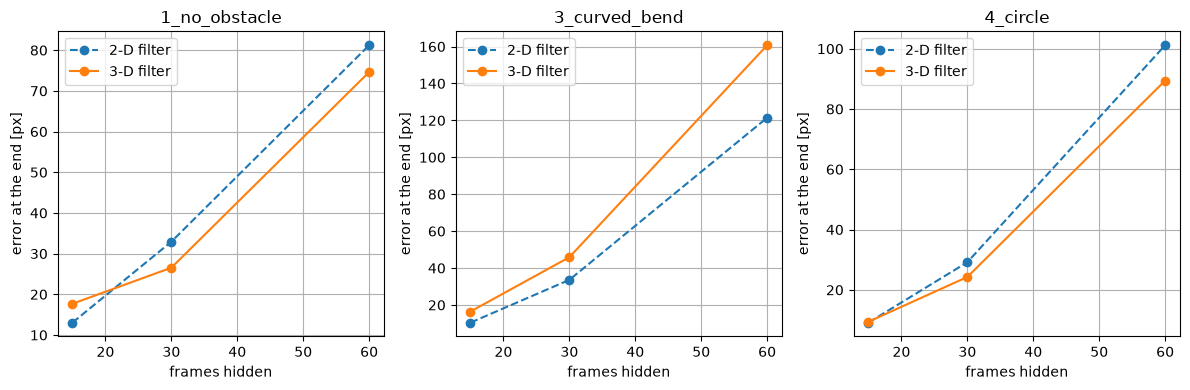

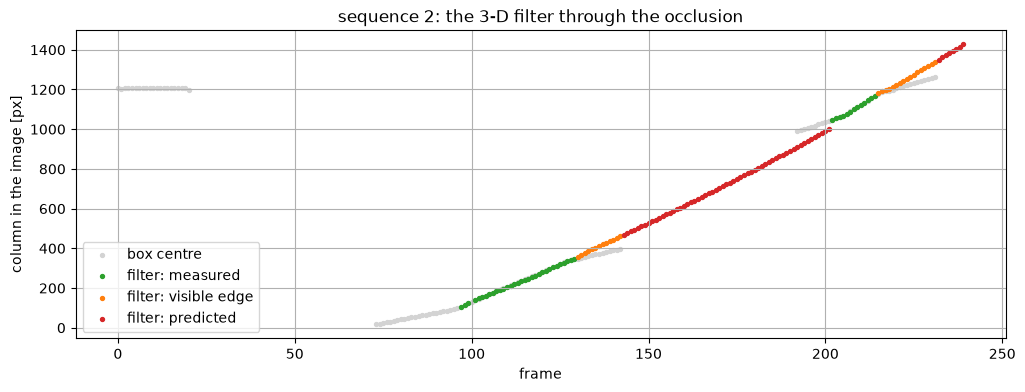

In [14]:
def image_position(state, mode):
    return state[:2] if mode == '2d' else to_image(state[:3])


rows = detections['2_obstacle']
labels = track(rows, '3d')[1]
last_seen = max(i for i, t in enumerate(labels) if t in ('full', 'edge') and i < 170)
back = next(i for i, t in enumerate(labels) if t == 'full' and i > 170)
print("sequence 2: last sign of the robot in frame", last_seen, "| first full box in frame", back,
      "| frames without any measurement:", sum(t == 'predicted' for t in labels[last_seen:back]))
_, bx, by, w, h, d, _ = rows[back]
for mode in ('2d', '3d'):
    for use_edges in (False, True):
        states = track(rows, mode, hide=(last_seen + 1, back + 1), use_edges=use_edges)[0]
        p = image_position(states[back], mode)
        text = mode + (' with' if use_edges else ' without') + ' visible edges: error ' + str(round(np.hypot(p[0] - (bx + w / 2), p[1] - (by + h)), 1)) + ' px'
        if mode == '3d':
            text += ', ' + str(round(np.linalg.norm(states[back][:3] - to_3d(bx + w / 2, by + h, d)), 3)) + ' m'
        print(" ", text)

GAPS = (15, 30, 60)
blackout = {}
print("hidden detections: RMS error at the end of the gap [px]")
for mode in ('2d', '3d'):
    for sequence in ('1_no_obstacle', '3_curved_bend', '4_circle'):
        rows = detections[sequence]
        labels = track(rows, mode)[1]
        full = [i for i, t in enumerate(labels) if t == 'full']
        result = []
        for gap in GAPS:
            errors = []
            for first in range(full[15], full[-1] - gap, 15):
                end = first + gap - 1
                if labels[end] != 'full':
                    continue
                state = track(rows, mode, hide=(first, first + gap))[0][end]
                if np.isnan(state[0]):
                    continue
                p = image_position(state, mode)
                errors.append(np.hypot(p[0] - (rows[end, 1] + rows[end, 3] / 2), p[1] - (rows[end, 2] + rows[end, 4])))
            result.append(np.sqrt(np.mean(np.square(errors))))
        blackout[mode, sequence] = result
        print(" ", mode, sequence, np.round(result, 1))

plt.figure(figsize=(12, 4))
for k, sequence in enumerate(('1_no_obstacle', '3_curved_bend', '4_circle')):
    plt.subplot(1, 3, k + 1)
    plt.plot(GAPS, blackout['2d', sequence], 'o--', label='2-D filter')
    plt.plot(GAPS, blackout['3d', sequence], 'o-', label='3-D filter')
    plt.xlabel('frames hidden')
    plt.ylabel('error at the end [px]')
    plt.title(sequence)
    plt.grid(True)
    plt.legend()
plt.tight_layout()
plt.show()

rows = detections['2_obstacle']
states, labels = track(rows, '3d')
labels = np.array(labels)
frames = np.arange(len(rows))
plt.figure(figsize=(12, 4))
plt.scatter(frames[rows[:, 0] >= MIN_AREA], rows[rows[:, 0] >= MIN_AREA, 1] + rows[rows[:, 0] >= MIN_AREA, 3] / 2, s=8, color='lightgray', label='box centre')
for name, (colour, text) in STYLES.items():
    chosen = labels == name
    plt.scatter(frames[chosen], [to_image(s[:3])[0] for s in states[chosen]], s=8, color=colour, label='filter: ' + text)
plt.xlabel('frame')
plt.ylabel('column in the image [px]')
plt.title('sequence 2: the 3-D filter through the occlusion')
plt.grid(True)
plt.legend()
plt.show()

#### Choosing the motion noise
The motion noise says how much the filter trusts its constant-velocity model. It is chosen from the hidden-detection test, not from the real occlusion, so that the real occlusion stays a fair test. The cell repeats the test for several values, at a coarser spacing so that it stays quick.

In [15]:
def blackout_error(mode, sequence, gap, step=30):
    rows = detections[sequence]
    labels = track(rows, mode)[1]
    full = [i for i, t in enumerate(labels) if t == 'full']
    errors = []
    for first in range(full[15], full[-1] - gap, step):
        end = first + gap - 1
        if labels[end] == 'full':
            state = track(rows, mode, hide=(first, first + gap))[0][end]
            if not np.isnan(state[0]):
                p = image_position(state, mode)
                errors.append(np.hypot(p[0] - (rows[end, 1] + rows[end, 3] / 2), p[1] - (rows[end, 2] + rows[end, 4])))
    return np.sqrt(np.mean(np.square(errors)))


chosen_2d, chosen_3d = MOTION_NOISE_2D, MOTION_NOISE_3D
print("RMS error [px] for gaps of 30 and 60 frames, sequences 1, 3, 4")
for value in (0.05, 0.1, 0.3, 1.0):
    MOTION_NOISE_2D = value
    print("  2-D, noise", value, "px:", [round(float(blackout_error('2d', q, g)), 1) for q in ('1_no_obstacle', '3_curved_bend', '4_circle') for g in (30, 60)])
for value in (0.03, 0.05, 0.1, 0.3):
    MOTION_NOISE_3D = value * SQUARE_SIZE
    print("  3-D, noise", value, "squares:", [round(float(blackout_error('3d', q, g)), 1) for q in ('1_no_obstacle', '3_curved_bend', '4_circle') for g in (30, 60)])
MOTION_NOISE_2D, MOTION_NOISE_3D = chosen_2d, chosen_3d

RMS error [px] for gaps of 30 and 60 frames, sequences 1, 3, 4
  2-D, noise 0.05 px: [36.0, 65.3, 42.6, 136.2, 38.0, 115.8]
  2-D, noise 0.1 px: [37.5, 67.8, 36.9, 126.4, 33.0, 107.6]
  2-D, noise 0.3 px: [40.8, 74.9, 32.3, 118.2, 28.4, 99.7]
  2-D, noise 1.0 px: [40.5, 81.3, 30.4, 113.8, 26.3, 95.6]
  3-D, noise 0.03 squares: [25.6, 122.5, 46.5, 163.3, 30.1, 110.1]
  3-D, noise 0.05 squares: [27.0, 86.9, 48.0, 166.9, 25.7, 96.7]
  3-D, noise 0.1 squares: [26.6, 45.0, 47.3, 162.7, 25.4, 89.1]
  3-D, noise 0.3 squares: [24.1, 20.6, 43.5, 151.1, 41.8, 128.4]


#### 11. The video
The project asks for a short video of the tracking on all four sequences. `cv2.VideoWriter` isn't a perception method and is used only to save the result. Each frame shows the rectified left image with the tracked box: green when measured, orange when only an edge is visible, and red when predicted. The insets show the disparity map and the track from above. It plays at 15 frames per second, about 5 times as fast as recorded, judging by the files' timestamps. Set `MAKE_VIDEO` to `False` to skip this cell, which takes about 3 minutes.

In [16]:
MAKE_VIDEO = True    # <- tweak

COLOURS = {'full': (0, 200, 0), 'init': (0, 200, 0), 'edge': (0, 165, 255), 'predicted': (0, 0, 255), 'gated': (0, 0, 255)}
VIDEO_SIZE = (960, 540)


def top_view(sequence, upto, size=(300, 200)):
    canvas = np.zeros((size[1], size[0], 3), np.uint8)
    ground = on_floor(tracks_3d[sequence][:, :3], floors[sequence][0])
    valid = ~np.isnan(ground[:, 0])
    low, high = ground[valid].min(axis=0), ground[valid].max(axis=0)
    scale = min((size[0] - 20) / max(high[0] - low[0], 1), (size[1] - 20) / max(high[1] - low[1], 1))
    for i in np.flatnonzero(valid[:upto + 1]):
        x, y = (ground[i] - low) * scale + 10
        colour = COLOURS.get(labels_3d[sequence][i], (255, 255, 255))
        cv2.circle(canvas, (int(x), int(size[1] - y)), 1, colour, -1)
    return canvas


if MAKE_VIDEO:
    start = time.time()
    writer = cv2.VideoWriter(os.path.join(RESULTS, 'husky_tracking.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), 15, VIDEO_SIZE)
    for sequence in SEQUENCES:
        rows, states, labels = detections[sequence], tracks_3d[sequence], labels_3d[sequence]
        width, height = 80, 80
        for i, (path_l, path_r) in enumerate(zip(image_files(sequence, 'left'), image_files(sequence, 'right'))):
            left, right = rectified(path_l, 'left'), rectified(path_r, 'right')
            disparity = disparity_map(left, right)
            if labels[i] in ('full', 'init'):
                width, height = int(rows[i, 3]), int(rows[i, 4])
            if not np.isnan(states[i, 0]):
                u, v = to_image(states[i, :3])
                cv2.rectangle(left, (int(u - width / 2), int(v - height)), (int(u + width / 2), int(v)), COLOURS.get(labels[i], (0, 0, 255)), 3)
                cv2.putText(left, 'X %.2f  Z %.2f m' % (states[i, 0], states[i, 2]), (int(u - width / 2), int(v + 28)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, COLOURS.get(labels[i], (0, 0, 255)), 2)
            frame = cv2.resize(left, VIDEO_SIZE)
            inset = cv2.resize(np.clip(disparity * 4, 0, 255).astype(np.uint8), (300, 169))
            frame[0:169, 660:960] = cv2.cvtColor(inset, cv2.COLOR_GRAY2BGR)
            frame[340:540, 660:960] = top_view(sequence, i)
            cv2.putText(frame, sequence + '  frame ' + str(i) + '  ' + labels[i], (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
            writer.write(frame)
    writer.release()
    print("video written in", round(time.time() - start, 1), "s,", round(os.path.getsize(os.path.join(RESULTS, 'husky_tracking.mp4')) / 1e6, 1), "MB")

video written in 103.9 s, 39.1 MB
